# Book Recommendation

This is a recommendation project.

Goodbooks-10k has users rating books from 1 to 5. This is not movies. I will look at the rating distribution and the most rated titles, then train two models on the same 80/20 split. The first is Truncated SVD on the user-book matrix. The second is a neural collaborative filter with embeddings. The deep model is the one I want here. I will compare RMSE and save the neural model.


In [1]:
import kagglehub

path = kagglehub.dataset_download("zygmunt/goodbooks-10k")
print("Path to dataset files:", path)


100%|██████████| 11.6M/11.6M [00:04<00:00, 3.03MB/s]

Extracting files...
Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\zygmunt\goodbooks-10k\versions\5


In [2]:
import os
import glob
import pandas as pd

ratings_path = glob.glob(os.path.join(path, "**", "ratings.csv"), recursive=True)[0]
ratings = pd.read_csv(ratings_path)
ratings = ratings.sample(n=200000, random_state=42)
ratings.head()


,book_id,user_id,rating
646451,6495,19643,5
614851,6175,8563,4
974393,9920,52110,3
21471,215,33864,5
272540,2728,16587,3


In [3]:
print(ratings.shape)
print(ratings["rating"].value_counts().sort_index())


(200000, 3)
rating
1     4050
2    12940
3    50689
4    72754
5    59567
Name: count, dtype: int64


In [4]:
books_path = glob.glob(os.path.join(path, "**", "books.csv"), recursive=True)[0]
books = pd.read_csv(books_path)
ratings = ratings.merge(books[["id", "title"]], left_on="book_id", right_on="id")
books.head()


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


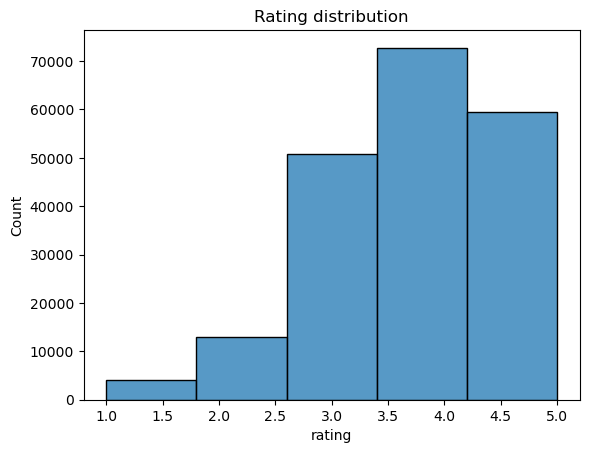

In [6]:
sns.histplot(data=ratings, x="rating", bins=5)
plt.title("Rating distribution")
plt.show()


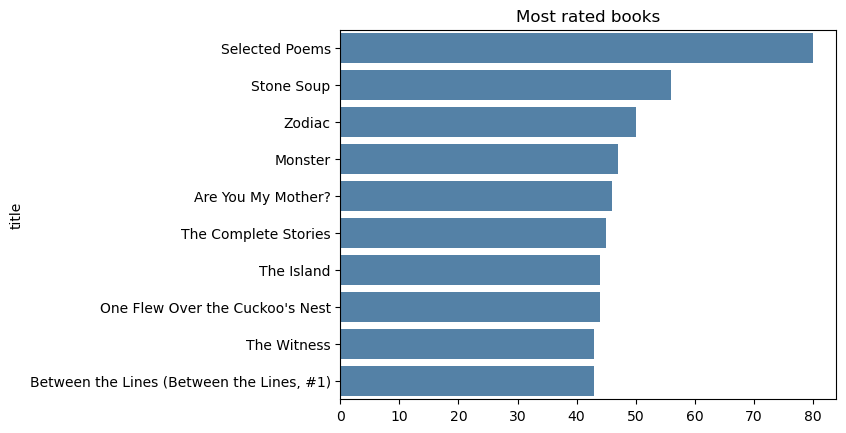

In [7]:
top = ratings["title"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Most rated books")
plt.show()


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

ue = LabelEncoder()
ie = LabelEncoder()
ratings["u"] = ue.fit_transform(ratings["user_id"])
ratings["i"] = ie.fit_transform(ratings["book_id"])
n_user = ratings["u"].nunique()
n_item = ratings["i"].nunique()

x_train, x_test, y_train, y_test = train_test_split(
    ratings[["u", "i"]], ratings["rating"], test_size=0.20, random_state=42
)
print(n_user, n_item)
print(x_train.shape, x_test.shape)


40534 9999
(160000, 2) (40000, 2)


In [9]:
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
import numpy as np

mat = coo_matrix(
    (y_train, (x_train["u"], x_train["i"])),
    shape=(n_user, n_item),
).tocsr()
svd = TruncatedSVD(n_components=32, random_state=42)
user_f = svd.fit_transform(mat)
svd_pred = (user_f[x_test["u"]] * svd.components_.T[x_test["i"]]).sum(axis=1)
print("SVD RMSE", np.sqrt(mean_squared_error(y_test, svd_pred)))


SVD RMSE 3.9485113469568955


In [10]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

user_in = layers.Input(shape=(1,))
item_in = layers.Input(shape=(1,))
u = layers.Flatten()(layers.Embedding(n_user, 32)(user_in))
it = layers.Flatten()(layers.Embedding(n_item, 32)(item_in))
x = layers.Concatenate()([u, it])
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1)(x)
dl = tf.keras.Model([user_in, item_in], out)
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    [x_train["u"], x_train["i"]], y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=256,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict([x_test["u"], x_test["i"]], verbose=0).ravel()
print("Neural CF RMSE", np.sqrt(mean_squared_error(y_test, dl_pred)))


Epoch 1/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3.5994 - val_loss: 0.8996
Epoch 2/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.9037 - val_loss: 0.8552
Epoch 3/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7783 - val_loss: 0.9010
Epoch 4/8
563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6979 - val_loss: 0.9547
Neural CF RMSE 0.9258523261877277


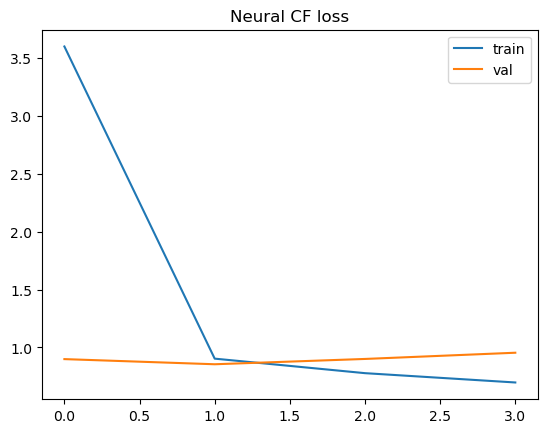

In [11]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("Neural CF loss")
plt.legend()
plt.show()


In [12]:
user = int(x_test["u"].iloc[0])
users = np.full((n_item, 1), user)
items = np.arange(n_item).reshape(-1, 1)
scores = dl([users, items], training=False).numpy().ravel()

seen = x_train.loc[x_train["u"] == user, "i"].to_numpy()
scores[seen] = -1

top = ie.inverse_transform(np.argsort(-scores)[:5])
print(books.loc[books["id"].isin(top), "title"])


5204                 The Stonekeeper's Curse (Amulet, #2)
5206    The Days Are Just Packed: A Calvin and Hobbes ...
6297                           The Poetry of Pablo Neruda
6919                  The Indispensable Calvin and Hobbes
9568                                      The Hate U Give
Name: title, dtype: object


In [13]:
dl.save("books_ncf.keras")


# Conclusion

I sampled 200000 Goodbooks ratings and trained Truncated SVD and a neural collaborative filter on the same split. This task is books, not movies. SVD is the classical matrix-factor baseline. The neural model learns embeddings for users and books and predicts the rating; that is the deep learning model here. RMSE is the number to watch. The neural model is saved as books_ncf.keras.
